# 生物光制氢：可检验的量子模型与过程情景

作者：曾祥洪 --QuantumBridge研发组

执行状态：本地状态向量与经典常微分方程计算；另保留夸父 Baihua 的 8 个已完成真机测量任务。局部角度由经典模拟器训练，真机用于固定参数推断，不称为硬件闭环 VQE。

本案例区分三个层次：生物文献中的真实机制、无量纲量子模型、机制启发的归一化过程模型。后二者不能直接预测实测产氢率。2025—2026 年研究用于确定应考察的机制与控制变量，不为作者设定的速率常数提供实验标定。

## 一 机制与近期技术

光系统 II 的水氧化可提供电子，电子经光合链及光系统 I 到达铁氧还蛋白；在适当条件下，氢酶将质子还原成氢气。氧抑制、竞争性电子去路与传质均影响该路径。近期整细胞调控、局部耗氧微环境与生物杂化材料研究是不同路线，不能视为一套装置的共同实验性能。

- 2025 年氧管理与 pgr5 藻株：[Physiologia Plantarum](https://pubmed.ncbi.nlm.nih.gov/40265210/)。
- 2026 年整细胞供电子与耗氧调控：[ChemCatChem](https://doi.org/10.1002/cmtd.70175)。
- 水氧化及电子来源的实验依据：[PNAS](https://pmc.ncbi.nlm.nih.gov/articles/PMC7703569/)。

## 二 可解析的量子模型

设 $H=Z\otimes Z+X\otimes I+I\otimes X$，能谱为 $\{-\sqrt5,-1,1,\sqrt5\}$。光学控制线为 $HP(\phi)H$；电子与质子标签仅代表模型自由度。保留 CNOT 与 CZ 两种受控门解释，明确八参数局部试探态，而不假定缺失配置。所有能量均无量纲。

对于 CNOT 读法，两个目标初始为 $|+\rangle$，故 $X|+\rangle=|+\rangle$，前端两次 CNOT 不产生所预想的纠缠。$P(111)=\sin^2(\phi/2)/4$。能量优化与该事件概率是不同目标。

对于 CZ 读法，跨光学线的 Schmidt 权重在后续局部酉变换下保持不变。可达最低能量受混合态谱限制，不能无条件达到 $-\sqrt5$。这是可解析、可数值核对的结构性差异。


In [1]:
from pathlib import Path
import sys, json, numpy as np
root=Path.cwd()
assert (root/'quantumbridge').is_dir(), 'Run from repository root'
sys.path.insert(0,str(root))
from scripts.biohydrogen_patent_model import export as run_quantum
from scripts.biohydrogen_process_model import export as run_process
data=root/'studio/downloads/biohydrogen-patent'
quantum=run_quantum(data)
process=run_process(data)
assert quantum['hardware_access'] is False
assert quantum['new_cloud_tasks']==0


{
  "spectrum": [
    -2.236067977499789,
    -1.0,
    0.9999999999999998,
    2.23606797749979
  ],
  "hardware_results": 0,
  "readings": {
    "text_cnot": {
      "initial": {
        "energy_dimensionless": 1.9999999999999987,
        "p111": 0.03661165235168153,
        "q0_purity": 0.9999999999999987,
        "probabilities_q0_first": {
          "000": 0.21338834764831832,
          "001": 0.21338834764831832,
          "010": 0.21338834764831832,
          "011": 0.21338834764831832,
          "100": 0.03661165235168153,
          "101": 0.03661165235168153,
          "110": 0.03661165235168153,
          "111": 0.03661165235168153
        }
      },
      "optimized_energy": -2.2360679774997876,
      "optimized_p111": 0.020238424056687722
    },
    "figure_cz": {
      "initial": {
        "energy_dimensionless": -1.563923685902801e-17,
        "p111": 0.03661165235168153,
        "q0_purity": 0.7499999999999991,
        "probabilities_q0_first": {
          "000": 0.21338

## 三 光照 氧与电子收支的过程模型

令 $e$ 为归一化电子库、$o$ 为氧、$a$ 为剩余活性氢酶分数，令 $v_s$ 为供电子通量、$v_h$ 为通向氢酶的电子通量、$v_c$ 为竞争去路、$v_r$ 为复合损失，则

$$\dot e=v_s-v_h-v_c-v_r,\quad \dot o=v_s/4-k_o o,\quad \dot a=-k_d o a,\quad \dot h=v_h/2.$$

具体采用 $v_s=k_s L(t)(1-e)$、$v_h=k_h\beta ae$、$v_c=k_c(1-\beta)e$、$v_r=k_re$。系数为明确记录的作者情景参数；未从论文拟合，归一化时间不等于秒或小时。不可逆失活为本模型的简化，未表示真实酶合成与修复。

在脉冲开闭点分段积分，使短脉冲不会被数值求解器跨越。对比情景保持相同入射光积分，但吸收、饱和及电子通量仍可不同。程序同时累计输入、竞争、复合和去氧账本。

## 四 实际计算与守恒核对


In [2]:
for name,row in process['scenarios'].items():
    s=row['summary']
    assert s['electron_balance_max_error']<1e-8
    assert s['oxygen_balance_max_error']<1e-8
    assert abs(s['incident_light_integral']-40)<1e-9
    print(name, json.dumps(s,ensure_ascii=False))
print('Charge, oxygen and incident-light checks passed; all outputs are model scenarios.')


constant_light {"H2_equivalents": 0.8907276334539551, "active_enzyme": 0.005308190824983853, "electron_balance_max_error": 5.773159728050814e-15, "oxygen_balance_max_error": 1.5543122344752192e-15, "incident_light_integral": 40.0}
pulsed_equal_photons {"H2_equivalents": 0.8864265413532572, "active_enzyme": 0.005797593218489951, "electron_balance_max_error": 7.993605777301127e-15, "oxygen_balance_max_error": 2.220446049250313e-15, "incident_light_integral": 40.0}
oxygen_management {"H2_equivalents": 2.4454635322294838, "active_enzyme": 0.22265636275146636, "electron_balance_max_error": 2.7977620220553945e-14, "oxygen_balance_max_error": 1.2878587085651816e-14, "incident_light_integral": 40.0}
electron_rerouting {"H2_equivalents": 1.2356159995722074, "active_enzyme": 0.009774420479826268, "electron_balance_max_error": 7.105427357601002e-15, "oxygen_balance_max_error": 4.440892098500626e-15, "incident_light_integral": 40.0}
combined_controls {"H2_equivalents": 3.2259449282230794, "active_

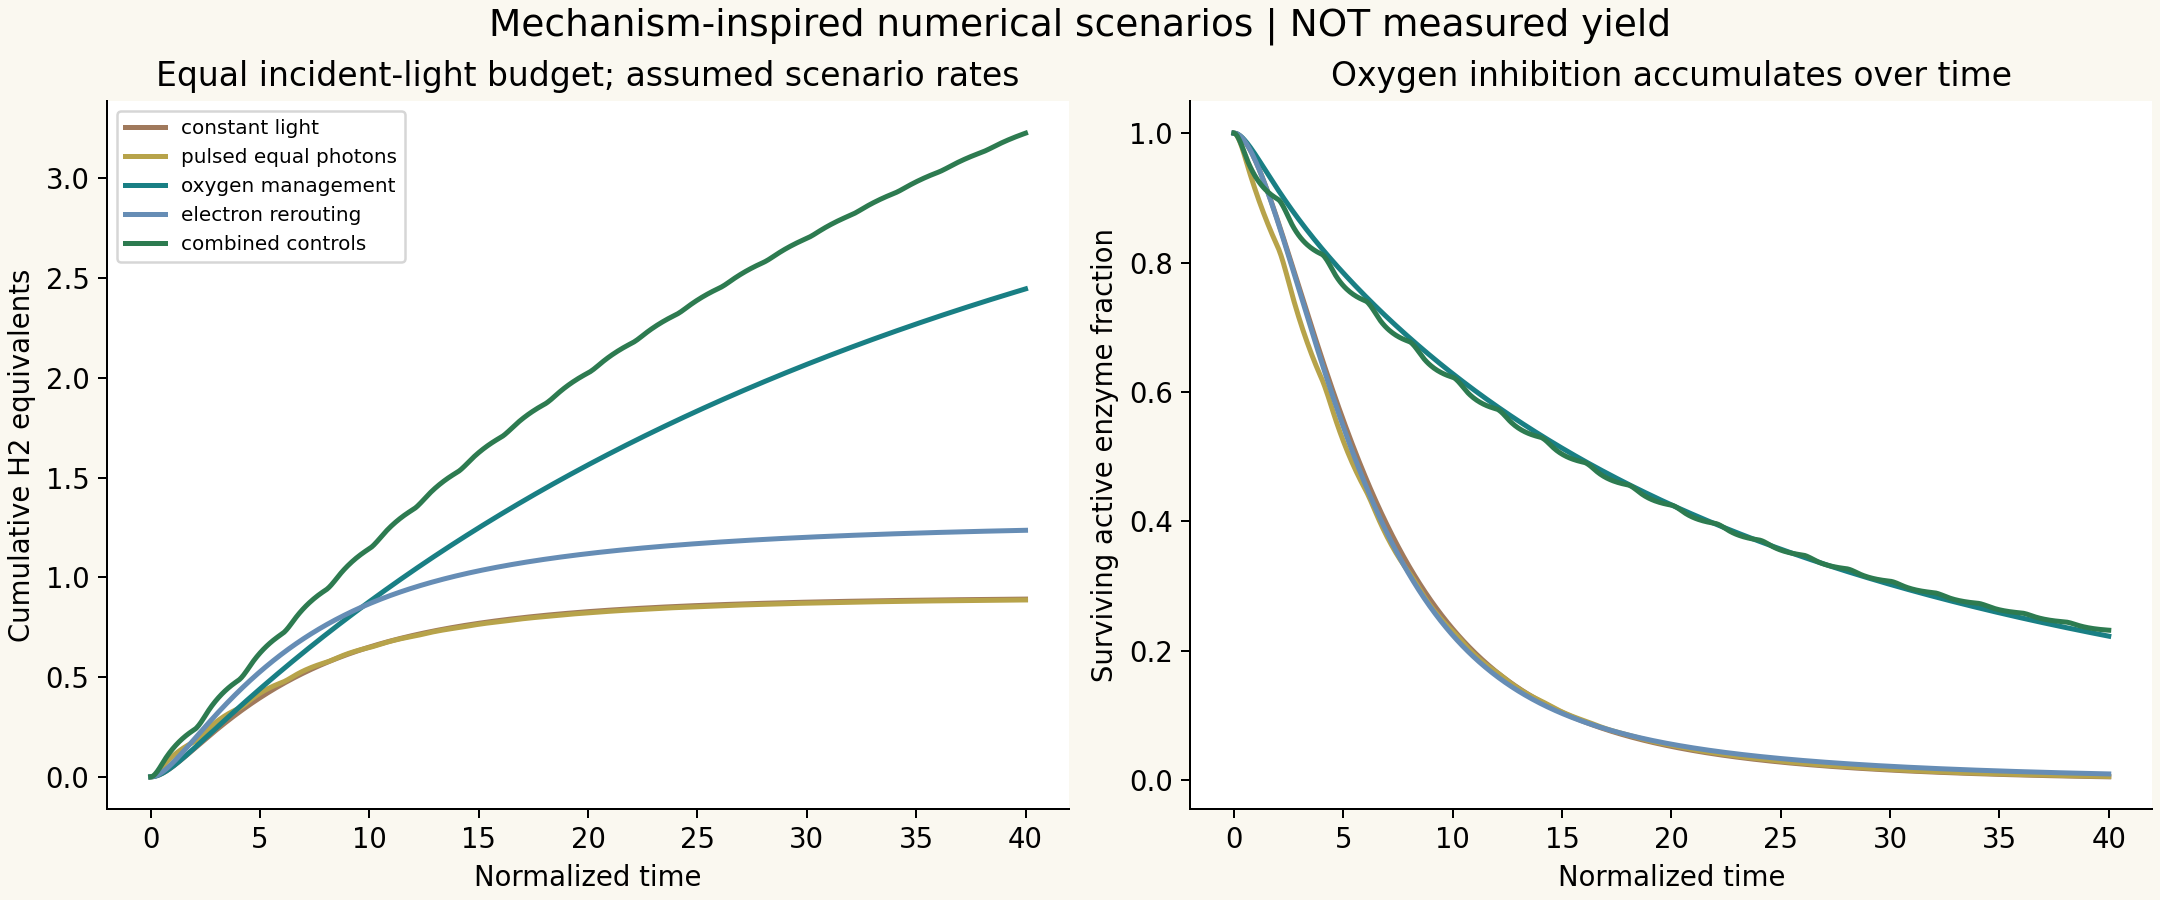

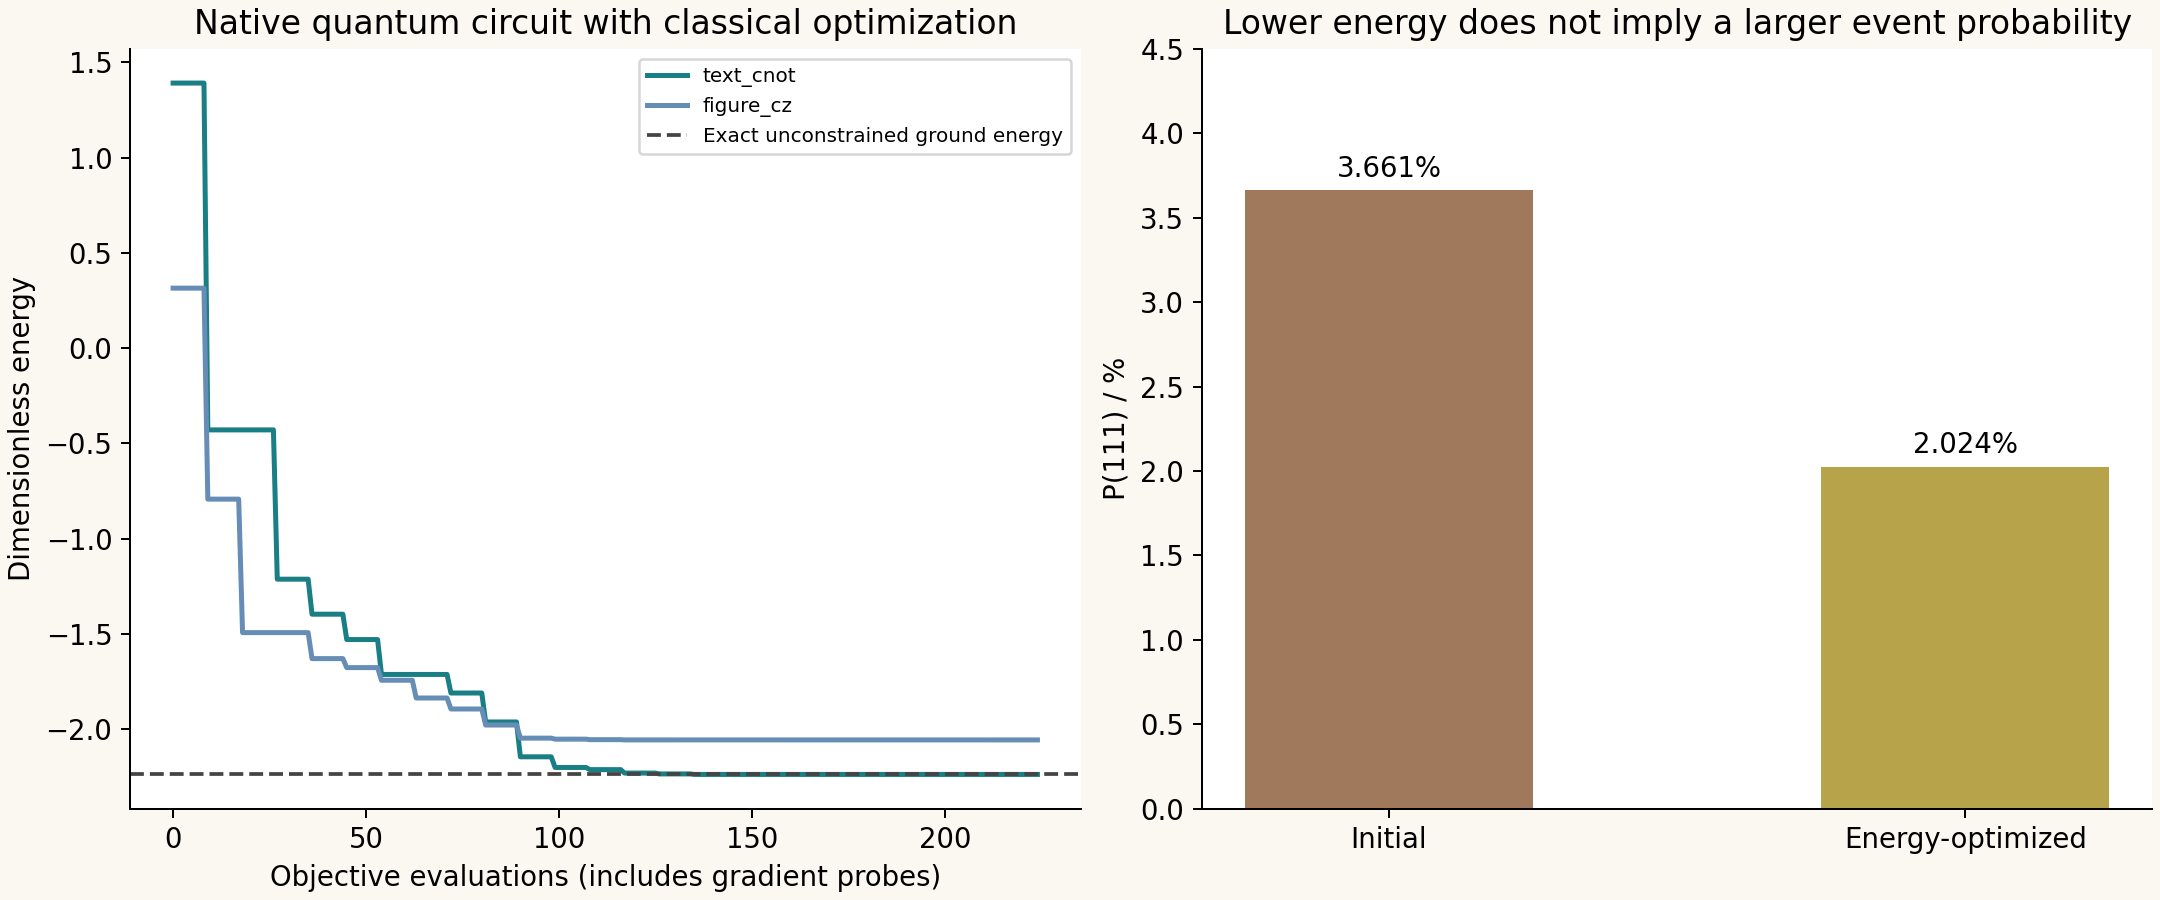

In [3]:
from IPython.display import display,Image
display(Image(filename=str(data/'process-comparison.png')))
display(Image(filename=str(data/'quantum-comparison.png')))


## 五 复现 测量方案与责任边界

从仓库根目录执行 `python3 -m scripts.biohydrogen_patent_model --output studio/downloads/biohydrogen-patent` 和 `python3 -m scripts.biohydrogen_process_model --output studio/downloads/biohydrogen-patent` 可重算记录。执行 `python3 scripts/build_biohydrogen_case.py` 重建本页面。

测试包括解析能谱、CNOT 恒等作用、Schmidt 约束、黑暗负对照、入射光预算、电子/氧守恒、非负性及步长收敛。动力学参数敏感性与真实培养体系标定仍是后续工作，不能用通过这些检查代替生物实验。

硬件方案包含 8 个测量电路：两种解释、初始/优化态、Z/X 测量基。ZZ 来自 Z 基，XI 与 IX 共享 X 基样本，合并能量不确定性时计入协方差。实际原始结果、校准标识、映射和执行线路保存在 hardware-evidence.json。标准误只描述有限采样，不能覆盖硬件系统偏差。

Anima 交互图：[从光到氢的可视化机制](/media/biohydrogen/)。


## 六 真实硬件测量及偏差

以下结果来自保留的官方完成回执。再次执行本 Notebook 只读取记录，不重新提交或消耗额度。

In [4]:
hardware=json.loads((data/'hardware-evidence.json').read_text())
assert hardware['verified_tasks']==8
for key,receipt in hardware['receipts'].items():
    assert receipt['mode']=='cloud_hardware' and receipt['status']=='Finished'
    assert sum(receipt['counts_q0_first'].values())==receipt['shots_returned']==1024
for row in hardware['rows']:
    print(json.dumps(row,ensure_ascii=False))
print('Raw hardware data include sizeable bias from ideal energies; this is not chemical or biological validation.')


{"reading": "text_cnot", "stage": "initial", "energy_dimensionless": 1.775390625, "standard_error": 0.03779813770198627, "p111": 0.03515625, "p111_wilson95": [0.025500926905294527, 0.048286190913159416], "ideal_energy_dimensionless": 1.9999999999999987, "ideal_p111": 0.03661165235168153, "energy_error_vs_local": -0.22460937499999867, "shots_per_basis": [1024, 1024], "task_ids": ["uc4e9da3f-261118-182516-0", "uc4e9da3f-261118-182522-0"], "total_variation_per_basis": [0.04442415235168168, 0.09765624999999951]}
{"reading": "text_cnot", "stage": "optimized", "energy_dimensionless": -1.3515625, "standard_error": 0.051300035491812626, "p111": 0.017578125, "p111_wilson95": [0.011147506606701729, 0.027614754322534085], "ideal_energy_dimensionless": -2.2360679774997876, "ideal_p111": 0.020238424056687722, "energy_error_vs_local": 0.8845054774997876, "shots_per_basis": [1024, 1024], "task_ids": ["uc4e9da3f-261118-182530-0", "uc4e9da3f-261118-182535-0"], "total_variation_per_basis": [0.1347398869